# Task4 — Supervised curriculum: restart from ImageNet

**Run All ฝึก EfficientNet-B0 fold1 จำนวน18epochs แล้วหยุดหลังvalidation**. เริ่มจาก ImageNet pretrained weights + headใหม่ ไม่ต่อจากโมเดลการแข่งขันเดิม และไม่ใช้teacher/KD/stacker. ImageNet pretrainedได้รับอนุญาตสำหรับTask4; ไม่ใช่random initialization

สูตรคงที่: AdamW backboneLR1e-4/headLR5e-4, weightdecay1e-4, cosine+warmup1epoch, batch32, workers0, seed42, weightedCEคำนวณจากtrainingfoldเท่านั้น. รักษาภาพเดิม30%; อีก70%เพิ่มcorruptionโดยseverityไล่จาก.35ถึง1ตลอด18epochs. teacherไม่มีอยู่ในtraininggraph

เพิ่มexposure/gamma/color, Gaussian noise, blur และrotationในสัดส่วนคงที่. ไม่เพิ่มJPEG/shot/impulseในสูตรฝึกนี้ แต่parentImageNetไม่ได้รับการตรวจว่าไม่เคยเห็นลักษณะเหล่านี้. ภาพTrainเองอาจมีnoiseอยู่แล้ว. ขอบดำ/resize/TTAเหมือนbaselineเพื่อไม่เปลี่ยนหลายจุดเพิ่ม

ประเมินภาพปกติและsyntheticstressบนvalidationfoldเดิม: รายงานmodelเดี่ยวและbaseline75%+curriculum25%. แยกคะแนน JPEG ที่ไม่อยู่ในaugmentationรอบนี้และworstcondition; ยังไม่เปิดauditเพื่อเลือกสูตร. ชุดvalidationเคยใช้ซ้ำจึงexploratory ไม่รับรองPublicscore

checkpointทุกepoch/resume; ถ้าหยุดกลางepochจะทำepochนั้นใหม่. ต้องrestart kernelก่อนRun AllและหยุดงานGPUอื่น. ประมาณ1ชั่วโมงเฉพาะฝึกจากB0เดิม ~205วินาที/epoch บวกvalidation; สูตรใหม่อาจต่างออกไป

**ไม่มีfold2–5, fullrefit, Test หรือexportในRun Allรอบนี้**. ตรวจfold1ก่อนลงทุนต่อ. ไม่ทับbaseline0.81047

In [1]:
from pathlib import Path
import sys, json, hashlib, time
import numpy as np
import pandas as pd
import torch
from dataclasses import asdict
from IPython.display import display
ROOT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'Task4/models/image_training.py').exists())
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
from Task4.models import image_curriculum_restart_training as training
from Task4.models import image_curriculum_restart_evaluation as evaluation
from Task4.models import image_compound_validation as validation
from Task4.models.image_audit import make_folds
from Task4.models.image_compound_transforms import CONDITIONS
RAW=ROOT/'Task4/data/raw'
AUDIT=ROOT/'Task4/data/audit/followup_v2'
OUT=ROOT/'Task4/models/results/curriculum_restart_v1'
BATCH_SIZE=32
NUM_WORKERS=0
NAME='curriculum_restart18'
print('Device:',training.get_device())
if training.get_device().type=='cpu':raise RuntimeError('CPU training would be slow: select the project kernel with MPS/CUDA available.')
display(asdict(training.RECIPES[NAME]))

Device: mps


{'architecture': 'efficientnet_b0',
 'epochs': 18,
 'backbone_lr': 0.0001,
 'head_lr': 0.0005,
 'weight_decay': 0.0001,
 'schedule': 'cosine',
 'warmup_epochs': 1,
 'augmentation': 'supervised_curriculum',
 'label_smoothing': 0.0,
 'seed': 42,
 'balance': 'weighted_loss',
 'jsd_weight': 0.0}

## 1. ตรวจ Train, fold separation และ references
Referencesใช้เปรียบเทียบเท่านั้น ไม่ใช่จุดเริ่มtraining. Original imagesผ่านการตรวจhashก่อนฝึก

In [2]:
train=pd.read_csv(RAW/'train.csv')
groups=pd.read_parquet(AUDIT/'train_groups.parquet')
assert train.id.is_unique and train.label.notna().all()
assert all(np.array_equal(train[c],groups[c]) for c in ['id','file_name','label'])
metadata=pd.read_parquet(AUDIT/'images.parquet',filters=[('split','=','train')]).set_index('id').loc[train.id]
assert metadata.split.eq('train').all()
inventory=hashlib.sha256()
for row in metadata.itertuples():
    assert Path(row.file_name).name==row.file_name
    digest=validation.sha(RAW/'train'/row.file_name)
    assert digest==row.sha256, f'Changed Train image: {row.file_name}'
    inventory.update(f'{row.file_name}/{digest}'.encode())
folds=make_folds(groups,mode='near',n_splits=5,seed=42)
fold_hash=hashlib.sha256(b''.join(v.astype('int64').tobytes() for _,v in folds)).hexdigest()
assert fold_hash==json.loads((ROOT/'Task4/models/results/heavy_balance_v1/settings.json').read_text())['fold_hash']
reference_hashes={}
for fold,(fit,valid) in enumerate(folds,1):
    assert not np.intersect1d(fit,valid).size
    assert not set(groups.iloc[fit].near_group)&set(groups.iloc[valid].near_group)
    for path in evaluation.references(ROOT,fold):
        signature=json.loads((path.parent/'signature.json').read_text())
        assert signature['data_signature']==validation.sha_frame(groups.iloc[fit])
        reference_hashes[str(path.relative_to(ROOT))]=validation.sha(path)
        frame=pd.read_parquet(path.parent/'oof.parquet')
        assert frame.id.tolist()==groups.iloc[valid].id.tolist()
        assert np.array_equal(frame.true,groups.iloc[valid].label)
        reference_hashes[str((path.parent/'oof.parquet').relative_to(ROOT))]=validation.sha(path.parent/'oof.parquet')
sources={p.name:validation.sha(p) for p in (ROOT/'Task4/models').glob('image_*.py')}
settings={'recipe':asdict(training.RECIPES[NAME]),'batch_size':BATCH_SIZE,'workers':NUM_WORKERS,
          'train_manifest':validation.sha(RAW/'train.csv'),'inventory':inventory.hexdigest(),'fold_hash':fold_hash,
          'references':reference_hashes,'sources':sources,'torch':str(torch.__version__),'device':str(training.get_device())}
OUT.mkdir(parents=True,exist_ok=True)
if (OUT/'settings.json').exists():assert json.loads((OUT/'settings.json').read_text())==settings,'Settings changed: use a new OUT'
else:
    assert not any(OUT.iterdir()),'Nonempty OUT without settings'
    validation.write_json(OUT/'settings.json',settings)
print('Train verified:',len(train),'rows; Test unopened')

Train verified: 31546 rows; Test unopened


## 2. Preview ภาพTrainก่อนฝึก
แสดงความยากต้น/ท้ายschedule ไม่ใช่ภาพTest; ภาพบางตัวอาจอยู่ใน30%ที่ไม่เพิ่มcorruption

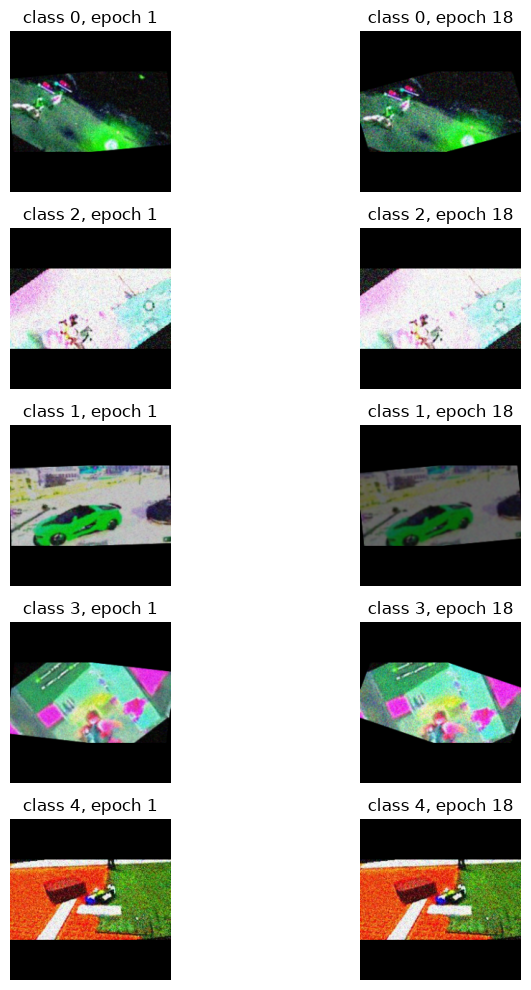

In [3]:
from Task4.models.image_supervised_curriculum import CurriculumImages
from Task4.models.image_training import MEAN,STD
import matplotlib.pyplot as plt
sample=groups.iloc[folds[0][0]].groupby('label').head(1).reset_index(drop=True)
ds=CurriculumImages(RAW,sample,training.RECIPES[NAME].epochs)
fig,axes=plt.subplots(len(ds),2,figsize=(9,2*len(ds)),squeeze=False)
for i in range(len(ds)):
    for j,epoch in enumerate([0,ds.epochs-1]):
        with torch.random.fork_rng():
            torch.manual_seed(100+i);ds.epoch=epoch;(x,),label=ds[i]
        rgb=(x*torch.tensor(STD)[:,None,None]+torch.tensor(MEAN)[:,None,None]).clamp(0,1)
        axes[i,j].imshow(rgb.permute(1,2,0));axes[i,j].set_title(f'class {label}, epoch {epoch+1}');axes[i,j].axis('off')
plt.tight_layout();plt.show()

## 3. Train CNN — fold1, 18epochs
มีเซลล์ฝึกเดียว. ใช้labelจริงเท่านั้น; lossไม่ใช่คะแนนvalidation และอาจเพิ่มเมื่อcurriculumยากขึ้น

In [5]:
started=time.monotonic()
frame=training.run_fold(RAW,groups,folds,NAME,1,OUT,BATCH_SIZE,NUM_WORKERS)
print('Train + original OOF minutes:',round((time.monotonic()-started)/60,1))
history=pd.read_json(OUT/NAME/'fold1/history.json')
display(history[['epoch','ce','curriculum_progress','seconds']])

fold1 epoch 3 / 18 loss 0.15965 seconds 206.8
fold1 epoch 4 / 18 loss 0.11794 seconds 207.4
fold1 epoch 5 / 18 loss 0.10203 seconds 205.0
fold1 epoch 6 / 18 loss 0.08001 seconds 201.7
fold1 epoch 7 / 18 loss 0.0681 seconds 200.9
fold1 epoch 8 / 18 loss 0.06034 seconds 219.1
fold1 epoch 9 / 18 loss 0.05458 seconds 244.1
fold1 epoch 10 / 18 loss 0.0534 seconds 206.3
fold1 epoch 11 / 18 loss 0.05027 seconds 194.7
fold1 epoch 12 / 18 loss 0.04315 seconds 195.3
fold1 epoch 13 / 18 loss 0.04257 seconds 197.2
fold1 epoch 14 / 18 loss 0.04303 seconds 198.1
fold1 epoch 15 / 18 loss 0.03933 seconds 192.9
fold1 epoch 16 / 18 loss 0.03992 seconds 198.4
fold1 epoch 17 / 18 loss 0.04602 seconds 195.1
fold1 epoch 18 / 18 loss 0.0484 seconds 195.0
Train + original OOF minutes: 55.6


,epoch,ce,curriculum_progress,seconds
0,1,0.576515,0.000000,209.521280
1,2,0.238402,0.058824,195.419297
2,3,0.159646,0.117647,206.799197
3,4,0.117935,0.176471,207.449643
4,5,0.102032,0.235294,205.045562
5,6,0.080007,0.294118,201.695648
6,7,0.068096,0.352941,200.937710
7,8,0.060336,0.411765,219.142474
8,9,0.054577,0.470588,244.079201
9,10,0.053399,0.529412,206.307036


## 4. Paired validation เทียบ baseline
เปรียบเทียบmodelเดี่ยวและblend25ด้วยภาพ/label/TTAชุดเดียวกัน. ไม่เปลี่ยนweightsหลังเห็นผล

In [ ]:
scores,overlap=evaluation.compare(ROOT,RAW,groups,folds,OUT,1,frame)
display(evaluation.summarize(scores))
w=scores.pivot(index='condition',columns='procedure',values='macro_F1')
display(w.assign(model_gain=w.curriculum-w.baseline,blend_gain=w.blend25-w.baseline))
display(overlap[overlap.condition.eq('original')])
s=scores.copy()
s['family']=s.condition.map(lambda c:'original' if c=='original' else ('compound' if c.startswith('compound_') else CONDITIONS[c][1]))
f=s.groupby(['procedure','family']).macro_F1.mean().unstack()
reports={}
for name in ['curriculum','blend25']:
    delta=f.loc[name]-f.loc['baseline']
    report={'original_gain':float(delta.original),'stress_family_gain':float(delta.drop('original').mean()),
            'worst_condition_gain':float((w[name]-w.baseline).min())}
    report['worth_reviewing']=bool(report['original_gain']>=-.001 and report['stress_family_gain']>=.002 and report['worst_condition_gain']>=-.02)
    reports[name]=report
validation.write_json(OUT/'pilot_report.json',{'fold':1,'reports':reports,'initialization':'ImageNet','teacher_used':False,'test_used':False,'automatic_continuation':False})
display(reports)
print('JPEG not added by this curriculum (reused validation, not untouched holdout):')
display(w.loc[['jpeg_1','jpeg_2']])
print('STOP: fold1 complete; no further training, Test inference or submission.')